
[notice] A new release of pip is available: 26.1.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


Training is Completed Successfully


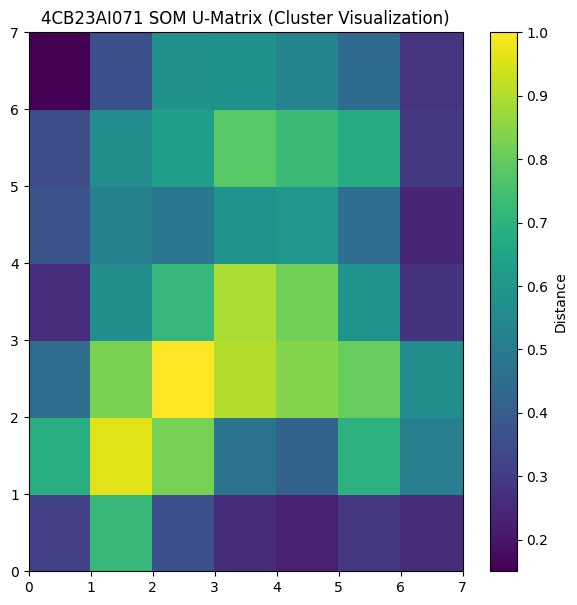


 4CB23AI071 Sample Cluster Assignments:
Data Point 1->Cluster(4,1)
Data Point 2->Cluster(2,1)
Data Point 3->Cluster(2,0)
Data Point 4->Cluster(2,0)
Data Point 5->Cluster(4,1)


In [18]:
!pip install minisom -q
#import libraries
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.preprocessing import MinMaxScaler
from minisom import MiniSom
#load Dataset
data=load_iris().data
#print(data)

scaler=MinMaxScaler()
data_scaled=scaler.fit_transform(data)
# print(data_scaled)

som=MiniSom(
    x=7,
    y=7,
    input_len=data_scaled.shape[1],
    sigma=1.0,
    learning_rate=0.5,
    random_seed=42
)
som.random_weights_init(data_scaled)
som.train_random(data_scaled,num_iteration=1000)
print("Training is Completed Successfully")

plt.figure(figsize=(7,7))
plt.pcolor(som.distance_map().T)
plt.colorbar(label="Distance")
plt.title("4CB23AI071 SOM U-Matrix (Cluster Visualization)")
plt.show()

clusters=[som.winner(x) for x in data_scaled]

print("\n 4CB23AI071 Sample Cluster Assignments:")
for i in range(5):
    x,y = clusters[i]
    print(f"Data Point {i+1}->Cluster({x},{y})")